In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/classified_reviews_4000_clean.csv")

In [3]:
print("Shape:", df.shape)
df.info()
display(df.head())

Shape: (3998, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3998 entries, 0 to 3997
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   review_id     3998 non-null   object
 1   sentiment     3998 non-null   object
 2   category      3998 non-null   object
 3   problem       1498 non-null   object
 4   summary       3998 non-null   object
 5   review_score  3998 non-null   int64 
 6   review_text   3998 non-null   object
dtypes: int64(1), object(6)
memory usage: 218.8+ KB


,review_id,sentiment,category,problem,summary,review_score,review_text
0,b25dd6669df8dfc0f1b3d64318665c2c,Positive,Other,NaN,The customer is very satisfied with the food c...,5,Os potes de mantimentos são lindíssimos! Estou...
1,5171e67b4c18d1c4c112eec0a237ad09,Positive,Delivery,Delayed delivery,The customer is satisfied and the product arri...,4,"Satisfeito. Demorou para chegar, mas o produto..."
2,34ae8d89fb26669bf28538c533ae6d8b,Negative,Delivery,Missing items in the shipment,The customer ordered two hoses but received on...,3,comprei 2 mangueiras e veio apenas 1
3,05a156b6eb9d7ae73f0338e1474764af,Positive,Delivery,NaN,Good quality product and delivered ahead of sc...,5,Produto de qualidade e entrega antes do prazo
4,e338c9c3b0a83b46d019e77b60cae1f6,Positive,Other,NaN,"Great customer service, delivery ahead of sche...",5,Atendemento Otimo Entrega Antes do praso E pro...


In [4]:
# 1. Duplicate IDs
print("Duplicate review IDs:", df["review_id"].duplicated().sum())

# 2. Sentiment values
print("\nSentiment values:")
print(df["sentiment"].value_counts())

# 3. Category values
print("\nCategory values:")
print(df["category"].value_counts())

# 4. Review score range
print("\nReview score range:")
print(df["review_score"].min(), "-", df["review_score"].max())

# 5. Empty strings
print("\nEmpty strings:")
print("review_text:", (df["review_text"].str.strip() == "").sum())
print("summary:", (df["summary"].str.strip() == "").sum())

Duplicate review IDs: 0

Sentiment values:
sentiment
Positive    2462
Negative    1191
Neutral      345
Name: count, dtype: int64

Category values:
category
Delivery               1634
Other                  1096
Product Quality         481
Product Description     295
Seller Service          215
Refund & Returns        115
Packaging                83
Payment & Pricing        79
Name: count, dtype: int64

Review score range:
1 - 5

Empty strings:
review_text: 0
summary: 0


In [5]:
print("Total non-null problems:", df["problem"].count())
print("Unique problem labels:", df["problem"].nunique())

display(
    df["problem"]
    .value_counts()
    .head(30)
    .reset_index()
)

Total non-null problems: 1498
Unique problem labels: 1114


,problem,count
0,Late delivery,39
1,Product not received,32
2,Delayed delivery,28
3,Missing item from order,19
4,Product not delivered,16
5,Missing item from the order,15
6,Order not received,14
7,Missing order,14
8,Incomplete order received,14
9,Delivery delay,14


In [ ]:
problem_counts = df["problem"].value_counts()

frequency_distribution = (
    problem_counts
    .value_counts()
    .sort_index()
    .rename_axis("reviews_per_label")
    .reset_index(name="number_of_labels")
)

display(frequency_distribution)

,reviews_per_label,number_of_labels
0,1,1019
1,2,45
2,3,14
3,4,13
4,5,2
5,6,5
6,7,2
7,8,1
8,9,2
9,10,1


In [10]:
print(frequency_distribution.to_string(index=False))
print(frequency_distribution.columns.tolist())

 reviews_per_label  number_of_labels
                 1              1019
                 2                45
                 3                14
                 4                13
                 5                 2
                 6                 5
                 7                 2
                 8                 1
                 9                 2
                10                 1
                14                 4
                15                 1
                16                 1
                19                 1
                28                 1
                32                 1
                39                 1
['reviews_per_label', 'number_of_labels']


In [11]:
problem_counts = df["problem"].value_counts()

frequent_problems = (
    problem_counts[problem_counts >= 3]
    .rename_axis("problem")
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(frequent_problems)

,problem,count
0,Late delivery,39
1,Product not received,32
2,Delayed delivery,28
3,Missing item from order,19
4,Product not delivered,16
5,Missing item from the order,15
6,Order not received,14
7,Missing order,14
8,Incomplete order received,14
9,Delivery delay,14


In [12]:
problem_mapping = {
    # Delivery delay
    "Late delivery": "Delivery delay",
    "Delayed delivery": "Delivery delay",
    "Delivery delay": "Delivery delay",
    "Delay in delivery": "Delivery delay",
    "Slow delivery": "Delivery delay",
    "Slight delivery delay": "Delivery delay",
    "Severe delivery delay": "Delivery delay",
    "Excessive delivery delay": "Delivery delay",
    "Slow delivery time": "Delivery delay",
    "Long delivery time": "Delivery delay",
    "Very delayed delivery": "Delivery delay",

    # Order not received
    "Product not received": "Order not received",
    "Product not delivered": "Order not received",
    "Order not received": "Order not received",
    "Missing order": "Order not received",
    "Product not yet received": "Order not received",
    "Order marked as delivered but not received": "Order not received",
    "Did not receive the product": "Order not received",
    "Order not yet received": "Order not received",
    "Order not received yet": "Order not received",
    "Order not delivered": "Order not received",
    "Order has not arrived yet": "Order not received",

    # Missing items
    "Missing item from order": "Missing items",
    "Missing item from the order": "Missing items",
    "Missing items in the shipment": "Missing items",
    "Missing items in order": "Missing items",
    "Missing items from the order": "Missing items",
    "Missing items in the order": "Missing items",
    "Missing items from order": "Missing items",
    "Incomplete order received": "Missing items",
    "Incomplete delivery": "Missing items",
    "Missing items in the delivered order": "Missing items",
    "Missing item in the delivery": "Missing items",
    "Incomplete order delivery": "Missing items",
    "Missing items in delivery": "Missing items",
    "Partial delivery of the order": "Missing items",
    "Missing items in the delivery": "Missing items",

    # Wrong product
    "Received the wrong product": "Wrong product",
    "Wrong item received": "Wrong product",
    "Wrong product received": "Wrong product",

    # Product quality
    "Poor product quality": "Product quality",
    "Defective product": "Product quality",

    # Shipping cost
    "High shipping cost": "Shipping cost",
    "Expensive shipping cost": "Shipping cost",

    # Other specific problems
    "Missing invoice": "Missing invoice",
    "Order cancelled due to out-of-stock product": "Out of stock cancellation",
    "General dissatisfaction": "General dissatisfaction"
}

In [13]:
print("Mapped labels:", len(problem_mapping))

mapped_reviews = df["problem"].map(problem_mapping).notna().sum()

print("Mapped reviews:", mapped_reviews)
print("Unmapped reviews:", df["problem"].notna().sum() - mapped_reviews)

Mapped labels: 47
Mapped reviews: 380
Unmapped reviews: 1118


In [14]:
unmapped_problems = (
    df.loc[
        df["problem"].notna() &
        ~df["problem"].isin(problem_mapping),
        "problem"
    ]
    .value_counts()
    .head(30)
    .rename_axis("problem")
    .reset_index(name="count")
)

display(unmapped_problems)

,problem,count
0,Late delivery and lack of updates,3
1,Product not delivered and refund requested,3
2,Late delivery and lack of communication from t...,3
3,Late delivery and missing order,2
4,Not received,2
5,Incorrect product delivered,2
6,Product received with a defect,2
7,Very long delivery time,2
8,Wrong color sent,2
9,Product arrived broken,2


In [15]:
additional_mapping = {
    "Late delivery and lack of updates": "Seller communication",
    "Product not delivered and refund requested": "Order not received",
    "Not received": "Order not received",
    "Incorrect product delivered": "Wrong product",
    "Product received with a defect": "Product quality",
    "Very long delivery time": "Delivery delay",
    "Wrong color sent": "Wrong product",
    "Product arrived broken": "Product quality",
    "Delivery delayed": "Delivery delay",
    "Waiting for order delivery": "Delivery delay",
    "Material is less resistant than expected": "Product quality",
    "Incorrect delivery status and missing order": "Order not received",
    "Delivery time was too long": "Delivery delay",
    "Invoice not issued": "Missing invoice",
    "Poor overall experience": "General dissatisfaction",
    "Missing part of the order": "Missing items",
    "Expensive shipping": "Shipping cost",
    "Product not yet delivered": "Order not received",
    "Very poor product quality": "Product quality",
    "Missing part": "Missing items",
    "Slow shipping": "Delivery delay",
    "Wrong product sent": "Wrong product",
    "Defective product with peeling strap": "Product quality",
    "Item marked as delivered but not received": "Order not received",
    "Shipping delay": "Delivery delay",
    "Received a completely different product": "Wrong product",
    "Incorrect product received": "Wrong product"
}

problem_mapping.update(additional_mapping)

In [16]:
mapped_reviews = df["problem"].map(problem_mapping).notna().sum()

print("Mapped labels:", len(problem_mapping))
print("Mapped reviews:", mapped_reviews)
print("Unmapped reviews:", df["problem"].notna().sum() - mapped_reviews)
print(
    "Coverage:",
    round(mapped_reviews / df["problem"].notna().sum() * 100, 2),
    "%"
)

Mapped labels: 74
Mapped reviews: 436
Unmapped reviews: 1062
Coverage: 29.11 %


In [17]:
unmapped_problems = (
    df.loc[
        df["problem"].notna() &
        ~df["problem"].isin(problem_mapping),
        "problem"
    ]
    .value_counts()
    .head(60)
    .rename_axis("problem")
    .reset_index(name="count")
)

display(unmapped_problems)

,problem,count
0,Late delivery and lack of communication from t...,3
1,Waiting for the product,2
2,Product is too fragile,2
3,Late delivery and item not received,2
4,Significant delivery delay,2
5,Delivery failure by the postal service,2
6,Received incorrect item,2
7,Product not working,2
8,Delivery issues caused by the postal service,2
9,Dented box,2


In [18]:
additional_mapping_2 = {
    "Waiting for the product": "Order not received",
    "Product is too fragile": "Product quality",
    "Late delivery and item not received": "Order not received",
    "Significant delivery delay": "Delivery delay",
    "Received incorrect item": "Wrong product",
    "Product not working": "Product quality",
    "Dented box": "Packaging",
    "Very slow delivery": "Delivery delay",
    "Inadequate packaging": "Packaging",
    "Missing item from the shipment": "Missing items",
    "missing order": "Order not received",
    "Incomplete delivery of ordered items": "Missing items",
    "Delayed delivery past the deadline": "Delivery delay",
    "Product differs from description": "Product description mismatch",
    "Delivery failure by the postal service": "Delivery issue",
    "Delivery issues caused by the postal service": "Delivery issue",
}

problem_mapping.update(additional_mapping_2)

In [19]:
mapped_reviews = df["problem"].map(problem_mapping).notna().sum()

print("Mapped labels:", len(problem_mapping))
print("Mapped reviews:", mapped_reviews)
print("Unmapped reviews:", df["problem"].notna().sum() - mapped_reviews)
print(
    "Coverage:",
    round(mapped_reviews / df["problem"].notna().sum() * 100, 2),
    "%"
)

Mapped labels: 90
Mapped reviews: 468
Unmapped reviews: 1030
Coverage: 31.24 %


In [20]:
unmapped = df.loc[
    df["problem"].notna() &
    ~df["problem"].isin(problem_mapping),
    "problem"
]

combined_problems = unmapped[
    unmapped.str.contains(
        "and|lack of|unresponsive|unable to contact",
        case=False,
        na=False
    )
]

display(combined_problems.value_counts().head(30))

problem
Late delivery and lack of communication from the seller                                                 3
Missing items and incorrect delivery status                                                             2
Late delivery and missing order                                                                         2
Missing items in order and unresponsive customer support                                                2
Unanswered contact attempts and delayed delivery                                                        1
Counterfeit and malfunctioning product                                                                  1
Lack of delivery information and missing shipment                                                       1
Product not received and requesting a refund                                                            1
Received a used product and unsuccessful exchange attempts                                              1
Damaged packaging and failure to deliv

In [21]:
problem_group_counts = (
    df["problem"]
    .map(problem_mapping)
    .value_counts()
    .rename_axis("problem_group")
    .reset_index(name="count")
)

display(problem_group_counts)

,problem_group,count
0,Delivery delay,129
1,Order not received,126
2,Missing items,122
3,Product quality,26
4,Wrong product,25
5,Shipping cost,11
6,General dissatisfaction,6
7,Missing invoice,6
8,Delivery issue,4
9,Out of stock cancellation,4


In [25]:
df["problem_group"] = pd.Series(
    pd.NA,
    index=df.index,
    dtype="object"
)

has_problem = df["problem"].notna()

df.loc[has_problem, "problem_group"] = (
    df.loc[has_problem, "problem"]
    .map(problem_mapping)
    .fillna("Other / Unclassified")
)

In [26]:
problem_group_counts = (
    df["problem_group"]
    .value_counts()
    .rename_axis("problem_group")
    .reset_index(name="count")
)

display(problem_group_counts)

,problem_group,count
0,Other / Unclassified,1030
1,Delivery delay,129
2,Order not received,126
3,Missing items,122
4,Product quality,26
5,Wrong product,25
6,Shipping cost,11
7,General dissatisfaction,6
8,Missing invoice,6
9,Delivery issue,4


In [27]:
print("Total rows:", len(df))
print("Non-null problem:", df["problem"].notna().sum())
print("Mapped problems:", (df["problem_group"] != "Other / Unclassified").sum())
print("Unclassified:", (df["problem_group"] == "Other / Unclassified").sum())

Total rows: 3998
Non-null problem: 1498
Mapped problems: 2968
Unclassified: 1030


In [28]:
print(df["problem_group"].value_counts(dropna=False))

problem_group
<NA>                            2500
Other / Unclassified            1030
Delivery delay                   129
Order not received               126
Missing items                    122
Product quality                   26
Wrong product                     25
Shipping cost                     11
General dissatisfaction            6
Missing invoice                    6
Delivery issue                     4
Out of stock cancellation          4
Packaging                          4
Seller communication               3
Product description mismatch       2
Name: count, dtype: int64


In [29]:
problem_sentiment = (
    df[df["problem_group"].notna()]
    .groupby(["problem_group", "sentiment"])
    .size()
    .unstack(fill_value=0)
)

problem_sentiment["total"] = problem_sentiment.sum(axis=1)

problem_sentiment["negative_pct"] = (
    problem_sentiment["Negative"] /
    problem_sentiment["total"] * 100
).round(2)

display(
    problem_sentiment
    .sort_values("negative_pct", ascending=False)
)

sentiment,Negative,Neutral,Positive,total,negative_pct
problem_group,,,,,
General dissatisfaction,6,0,0,6,100.00
Out of stock cancellation,4,0,0,4,100.00
Product description mismatch,2,0,0,2,100.00
Seller communication,3,0,0,3,100.00
Missing items,114,7,1,122,93.44
Product quality,24,2,0,26,92.31
Order not received,115,11,0,126,91.27
Wrong product,22,2,1,25,88.00
Other / Unclassified,789,189,52,1030,76.60


In [30]:
negative_total = (df["sentiment"] == "Negative").sum()

problem_sentiment["share_of_all_negative"] = (
    problem_sentiment["Negative"] / negative_total * 100
).round(2)

display(
    problem_sentiment[
        ["Negative", "total", "negative_pct", "share_of_all_negative"]
    ]
    .sort_values("Negative", ascending=False)
)

sentiment,Negative,total,negative_pct,share_of_all_negative
problem_group,,,,
Other / Unclassified,789,1030,76.60,66.25
Order not received,115,126,91.27,9.66
Missing items,114,122,93.44,9.57
Delivery delay,96,129,74.42,8.06
Product quality,24,26,92.31,2.02
Wrong product,22,25,88.00,1.85
General dissatisfaction,6,6,100.00,0.50
Shipping cost,5,11,45.45,0.42
Out of stock cancellation,4,4,100.00,0.34


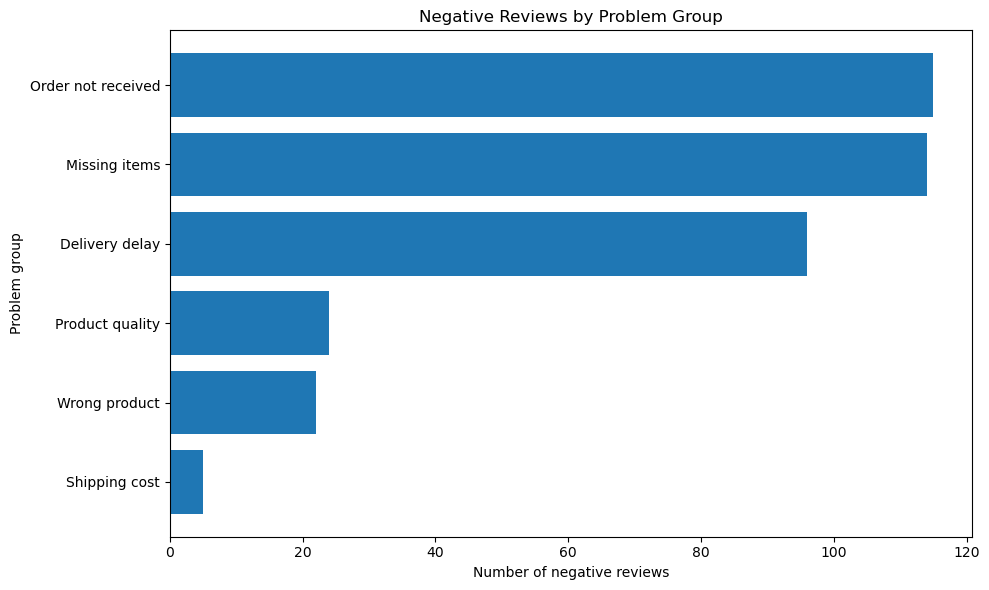

In [31]:
problem_chart = (
    problem_sentiment
    .loc[
        (problem_sentiment.index != "Other / Unclassified") &
        (problem_sentiment["total"] >= 10)
    ]
    .sort_values("Negative")
)

plt.figure(figsize=(10, 6))

plt.barh(
    problem_chart.index,
    problem_chart["Negative"]
)

plt.xlabel("Number of negative reviews")
plt.ylabel("Problem group")
plt.title("Negative Reviews by Problem Group")

plt.tight_layout()
plt.show()

In [32]:
problem_chart_table = problem_chart[
    ["Negative", "Neutral", "Positive", "total", "negative_pct"]
].sort_values("Negative", ascending=False)

problem_chart_table

sentiment,Negative,Neutral,Positive,total,negative_pct
problem_group,,,,,
Order not received,115,11,0,126,91.27
Missing items,114,7,1,122,93.44
Delivery delay,96,25,8,129,74.42
Product quality,24,2,0,26,92.31
Wrong product,22,2,1,25,88.00
Shipping cost,5,5,1,11,45.45


In [34]:
print("Total negative reviews in selected groups:",
      problem_chart_table["Negative"].sum())

print("Total reviews in selected groups:",
      problem_chart_table["total"].sum())

Total negative reviews in selected groups: 376
Total reviews in selected groups: 439


In [38]:
hz =(
    df.assign(is_neg=df['sentiment'] == 'Negative')
    .groupby('category', as_index=False)
    .agg(
        total_reviews=('sentiment', 'size'),
        negative_count=('is_neg', 'sum'),
        negative_rate=('is_neg', lambda x: (x.mean() * 100).round(2)),
    ).sort_values('negative_rate', ascending=False)
)
hz

,category,total_reviews,negative_count,negative_rate
6,Refund & Returns,115,99,86.09
4,Product Description,295,185,62.71
7,Seller Service,215,103,47.91
2,Packaging,83,33,39.76
5,Product Quality,481,178,37.01
3,Payment & Pricing,79,27,34.18
0,Delivery,1634,546,33.41
1,Other,1096,20,1.82


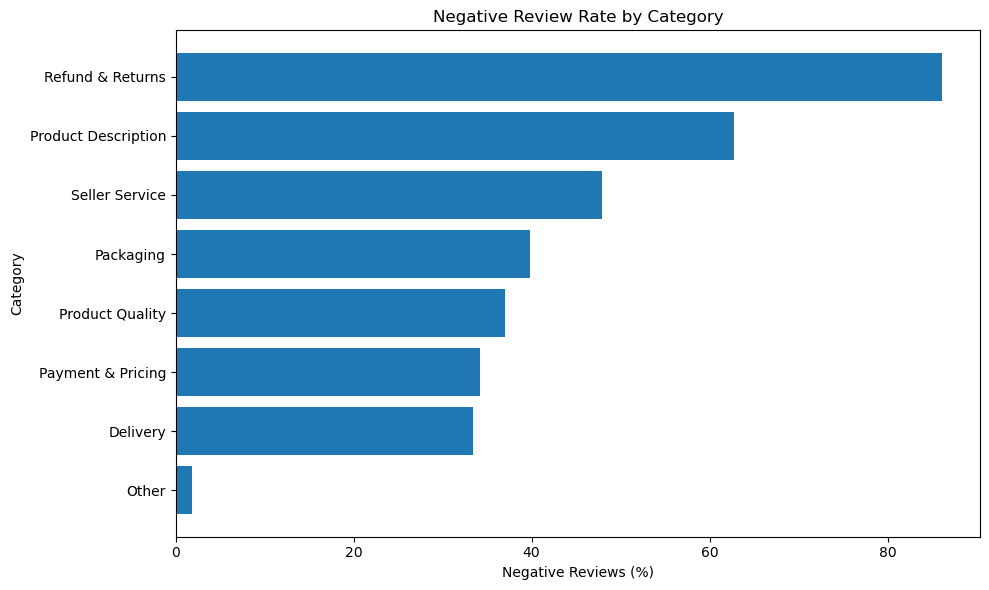

In [40]:
plt.figure(figsize=(10, 6))

plt.barh(
    hz['category'].iloc[::-1],
    hz['negative_rate'].iloc[::-1]
)

plt.xlabel('Negative Reviews (%)')
plt.ylabel('Category')
plt.title('Negative Review Rate by Category')

plt.tight_layout()
plt.show()

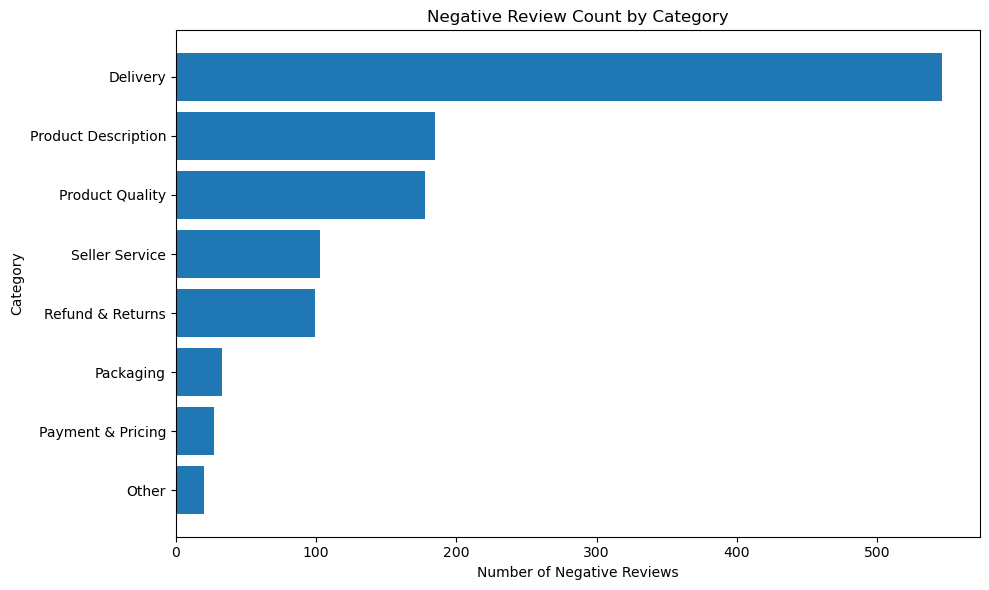

In [42]:
count_chart = hz.sort_values('negative_count', ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    count_chart['category'],
    count_chart['negative_count']
)

plt.xlabel('Number of Negative Reviews')
plt.ylabel('Category')
plt.title('Negative Review Count by Category')

plt.tight_layout()
plt.show()

In [45]:
cond_high_neg = df['review_score'].isin([4, 5]) & (df['sentiment'] == 'Negative')
count_high_neg = cond_high_neg.sum()

cond_low_pos = df['review_score'].isin([1, 2]) & (df['sentiment'] == 'Positive')
count_low_pos = cond_low_pos.sum()

print(f"Оцінка 4-5, але Negative: {count_high_neg}")
print(f"Оцінка 1-2, але Positive: {count_low_pos}")
print(f"Загальна кількість: {count_low_pos.sum() + cond_high_neg.sum()}")

Оцінка 4-5, але Negative: 93
Оцінка 1-2, але Positive: 21
Загальна кількість: 114


In [56]:
hz_1 = df[
    ((df['review_score'].isin([4, 5])) & (df['sentiment'] == 'Negative')) | 
    ((df['review_score'].isin([1, 2])) & (df['sentiment'] == 'Positive'))].copy()

In [ ]:
hz_1.groupby("category").size()

category
Delivery               32
Other                  15
Packaging               7
Payment & Pricing       6
Product Description    16
Product Quality        25
Refund & Returns        5
Seller Service          8
dtype: int64

In [58]:
before_filter = df.groupby('category').size().rename('before_filters')

after_filter = df[
    ((df['review_score'].isin([4, 5])) & (df['sentiment'] == 'Negative')) | 
    ((df['review_score'].isin([1, 2])) & (df['sentiment'] == 'Positive'))].copy()

after_filter = after_filter.groupby('category').size().rename('after_filters')

In [ ]:
summary = pd.concat([before_filter, after_filter], axis=1).fillna(0)
summary['mismatch_rate'] = (summary['after_filters'] / summary['before_filters'] * 100).round(2)
summary

,before_filters,after_filters,percentage_%
category,,,
Delivery,1634,32,1.96
Other,1096,15,1.37
Packaging,83,7,8.43
Payment & Pricing,79,6,7.59
Product Description,295,16,5.42
Product Quality,481,25,5.20
Refund & Returns,115,5,4.35
Seller Service,215,8,3.72


In [61]:
hz_2 = df[
    ((df['review_score'].isin([4, 5])) & (df['sentiment'] == 'Negative')) | 
    ((df['review_score'].isin([1, 2])) & (df['sentiment'] == 'Positive'))].copy()

In [62]:
hz_2.groupby(['category','sentiment']).size().rename('after_filters')

category             sentiment
Delivery             Negative     29
                     Positive      3
Other                Negative      2
                     Positive     13
Packaging            Negative      7
Payment & Pricing    Negative      6
Product Description  Negative     16
Product Quality      Negative     21
                     Positive      4
Refund & Returns     Negative      5
Seller Service       Negative      7
                     Positive      1
Name: after_filters, dtype: int64

In [63]:
df.columns.tolist()

['review_id',
 'sentiment',
 'category',
 'problem',
 'summary',
 'review_score',
 'review_text',
 'problem_group']

In [71]:
df_delivery = df[df['category'] == 'Delivery'].copy()

In [72]:
df_delivery.groupby('problem_group').size()

problem_group
Delivery delay          129
Delivery issue            4
Missing items           115
Order not received      124
Other / Unclassified    298
Seller communication      3
dtype: int64

In [73]:
delivery_sentiment = (
    df[df["category"] == "Delivery"]
    .groupby(["problem_group", "sentiment"])
    .size()
    .unstack(fill_value=0)
)

delivery_sentiment["total"] = delivery_sentiment.sum(axis=1)

delivery_sentiment["negative_pct"] = (
    delivery_sentiment["Negative"] /
    delivery_sentiment["total"] * 100
).round(2)

delivery_sentiment.sort_values("Negative", ascending=False)

sentiment,Negative,Neutral,Positive,total,negative_pct
problem_group,,,,,
Other / Unclassified,223,58,17,298,74.83
Order not received,113,11,0,124,91.13
Missing items,108,7,0,115,93.91
Delivery delay,96,25,8,129,74.42
Delivery issue,3,1,0,4,75.00
Seller communication,3,0,0,3,100.00


In [74]:
df_product_description = df[df['category'] == 'Product Description'].copy()

In [75]:
df_product_description.groupby('problem_group').size()

problem_group
Missing items                     1
Other / Unclassified            211
Product description mismatch      2
Wrong product                    23
dtype: int64

In [76]:
delivery_sentiment = (
    df[df["category"] == "Product Description"]
    .groupby(["problem_group", "sentiment"])
    .size()
    .unstack(fill_value=0)
)

delivery_sentiment["total"] = delivery_sentiment.sum(axis=1)

delivery_sentiment["negative_pct"] = (
    delivery_sentiment["Negative"] /
    delivery_sentiment["total"] * 100
).round(2)

delivery_sentiment.sort_values("Negative", ascending=False)

sentiment,Negative,Neutral,Positive,total,negative_pct
problem_group,,,,,
Other / Unclassified,161,42,8,211,76.3
Wrong product,21,1,1,23,91.3
Product description mismatch,2,0,0,2,100.0
Missing items,1,0,0,1,100.0


In [77]:
df_refund_and_returns = df[df['category'] == 'Refund & Returns'].copy()

In [78]:
df_refund_and_returns.groupby('problem_group').size()

problem_group
Missing items                  2
Order not received             2
Other / Unclassified         104
Out of stock cancellation      4
Product quality                1
Wrong product                  1
dtype: int64

In [79]:
delivery_sentiment = (
    df[df["category"] == "Refund & Returns"]
    .groupby(["problem_group", "sentiment"])
    .size()
    .unstack(fill_value=0)
)

delivery_sentiment["total"] = delivery_sentiment.sum(axis=1)

delivery_sentiment["negative_pct"] = (
    delivery_sentiment["Negative"] /
    delivery_sentiment["total"] * 100
).round(2)

delivery_sentiment.sort_values("Negative", ascending=False)

sentiment,Negative,Neutral,Positive,total,negative_pct
problem_group,,,,,
Other / Unclassified,90,12,2,104,86.54
Out of stock cancellation,4,0,0,4,100.00
Missing items,2,0,0,2,100.00
Order not received,2,0,0,2,100.00
Product quality,1,0,0,1,100.00
Wrong product,0,1,0,1,0.00
